# 2. Aprendizaje no supervisado

**Pronóstico del consumo eléctrico residencial por distrito con aprendizaje automático** · Sistemas Inteligentes · Grupo 6 · UNMSM

**Objetivo.** Agrupar los distritos según su perfil mensual de consumo (k-means, contrastado con un agrupamiento jerárquico y visualizado con PCA) y detectar distrito-meses atípicos con DBSCAN.

| | |
|---|---|
| **Entradas** | `datos/procesados/panel.parquet` |
| **Salidas** | `modelos/kmeans_distritos.joblib` y `modelos/kmeans_distritos.json` (escalador, modelo, numeración de grupos y métricas) |

### Índice

1. [Configuración](#configuración)
2. [Perfil mensual de cada distrito](#perfil-mensual-de-cada-distrito)
3. [k-means: elección del número de grupos](#k-means-elección-del-número-de-grupos)
4. [Los grupos de distritos](#los-grupos-de-distritos)
5. [Visualización con PCA](#visualización-con-pca)
6. [Contraste con el agrupamiento jerárquico](#contraste-con-el-agrupamiento-jerárquico)
7. [Detección de atípicos con DBSCAN](#detección-de-atípicos-con-dbscan)
8. [Exportación del modelo k-means](#exportación-del-modelo-k-means)
9. [Verificación con el informe](#verificación-con-el-informe)
10. [Conclusiones](#conclusiones)
11. [Referencias](#referencias)

<a id="configuración"></a>

## 1. Configuración

Importaciones, estilo, versiones y semilla, panel distrito-mes y resultados publicados para la verificación final.

In [1]:
import importlib
import json
import time
import warnings

import estilo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from estilo import AQUA, BLUE, COLOR_GRUPO, CYAN, GRIS, MESES, NAVY, SKY, coma

from ml import config

estilo.aplicar()
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
INFORME = json.loads(config.RESULTADOS.read_text(encoding="utf8"))  # resultados publicados
RESUMEN = json.loads(config.RESUMEN_PREPROCESAMIENTO.read_text(encoding="utf8"))
INICIO = time.time()
MODULOS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scikit-learn": "sklearn",
    "scipy": "scipy",
    "xgboost": "xgboost",
    "matplotlib": "matplotlib",
}
VERSIONES = {n: importlib.import_module(m).__version__ for n, m in MODULOS.items()}
print("Semilla:", config.SEMILLA)
print(" · ".join(f"{n} {v}" for n, v in VERSIONES.items()))

from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from ml import caracteristicas as car
from ml.agrupamiento import (
    dbscan_atipicos,
    jerarquico_distritos,
    kmeans_distritos,
    perfiles_mensuales,
    proyeccion_pca,
    resumen_grupos,
    rodilla,
)

pn = car.ordenar(pd.read_parquet(config.PANEL))
print(f"Panel: {pn['UBIGEO'].nunique()} distritos × {pn['PERIODO'].nunique()} meses")

Semilla: 42
numpy 2.4.6 · pandas 3.1.1 · scikit-learn 1.9.1 · scipy 1.17.1 · xgboost 3.2.0 · matplotlib 3.11.2


Panel: 78 distritos × 34 meses


<a id="perfil-mensual-de-cada-distrito"></a>

## 2. Perfil mensual de cada distrito

Cada distrito se describe con su **consumo medio de cada mes del año** en 2024 y 2025 (12 valores); 2026 se reserva para la prueba de los modelos supervisados, de modo que el agrupamiento no usa información del periodo de prueba.

Dos transformaciones, y por qué:

- **Logaritmo:** las diferencias entre distritos son multiplicativas (unos consumen cuatro veces más que otros); en logaritmo, una misma proporción pesa igual en cualquier nivel.
- **Estandarización por mes:** cada mes queda con media 0 y desviación 1, para que ningún mes domine las distancias euclidianas.

In [2]:
perfiles = perfiles_mensuales(pn)
X = StandardScaler().fit_transform(np.log(perfiles.values))
print("Matriz de entrada:", X.shape, "(distritos × meses)")
perfiles.round(1).head()

Matriz de entrada: (78, 12) (distritos × meses)


mes,1,2,3,4,5,6,7,8,9,10,11,12
UBIGEO,,,,,,,,,,,,
200101,162.0000,167.9000,191.0000,179.6000,161.3000,151.4000,145.5000,145.6000,143.2000,150.0000,150.6000,154.0000
200104,140.4000,144.4000,158.3000,142.6000,132.0000,123.5000,123.7000,122.7000,122.0000,126.1000,128.5000,133.0000
200105,100.7000,101.5000,115.3000,106.7000,97.8000,92.2000,89.8000,93.2000,89.6000,93.5000,94.1000,98.1000
200107,57.5000,55.5000,63.3000,60.8000,53.9000,50.2000,52.1000,52.2000,52.3000,54.1000,53.1000,57.2000
200108,48.4000,49.0000,55.8000,51.3000,50.6000,44.9000,43.8000,46.3000,46.5000,48.6000,48.0000,49.8000


<a id="k-means-elección-del-número-de-grupos"></a>

## 3. k-means: elección del número de grupos

k-means asigna cada distrito al centroide más cercano y recalcula los centroides hasta que nada cambia (Lloyd, 1982); minimiza la suma de cuadrados dentro de los grupos:

$$\mathrm{SSE} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

La SSE siempre baja al aumentar $K$, así que no sirve sola para elegirlo: se combina con el **método del codo** y con el **coeficiente de silueta** (Rousseeuw, 1987), que sí penaliza los grupos mal separados:

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}$$

donde $a(i)$ es la distancia media del punto a su grupo y $b(i)$ al grupo vecino más cercano. Cada $K$ se ajusta con 20 inicializaciones para no depender de un mal punto de partida.

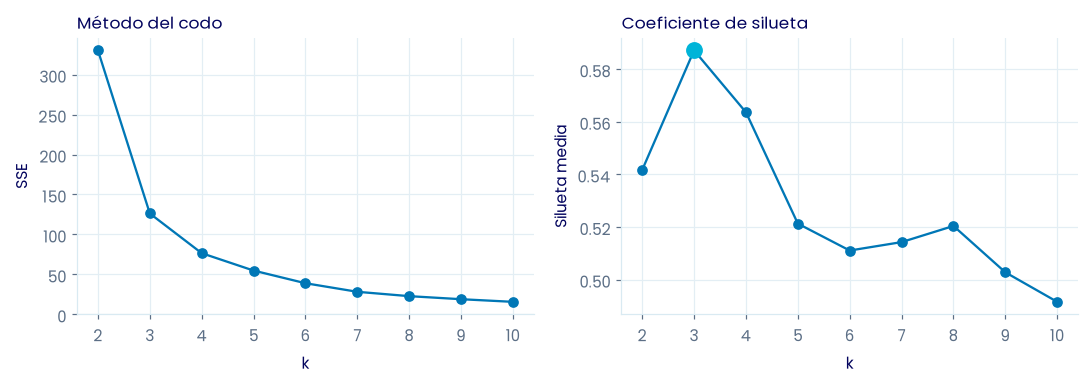

,2,3,4,5,6,7,8,9,10
SSE,330.2770,126.1790,76.5160,54.7640,38.9200,28.1910,22.7490,18.9300,15.6330
silueta,0.5420,0.5870,0.5640,0.5210,0.5110,0.5140,0.5200,0.5030,0.4920


In [3]:
ks = range(2, 11)
sse, sil = {}, {}
for k in ks:
    m = KMeans(n_clusters=k, n_init=20, random_state=config.SEMILLA).fit(X)
    sse[k], sil[k] = m.inertia_, silhouette_score(X, m.labels_)
k_opt = max(sil, key=sil.get)
fig, (a1, a2) = plt.subplots(1, 2)
a1.plot(list(ks), [sse[k] for k in ks], color=BLUE, marker="o")
a1.set(title="Método del codo", xlabel="k", ylabel="SSE")
a2.plot(list(ks), [sil[k] for k in ks], color=BLUE, marker="o")
a2.plot([k_opt], [sil[k_opt]], "o", color=CYAN, ms=10)
a2.set(title="Coeficiente de silueta", xlabel="k", ylabel="Silueta media")
plt.tight_layout()
plt.show()
pd.DataFrame({"SSE": sse, "silueta": sil}).T.round(3)

La SSE baja con fuerza hasta k = 3 y después lo hace de forma gradual; la silueta media alcanza su máximo en **k = 3** (0,587), frente a 0,542 con dos grupos y 0,564 con cuatro. Se adopta k = 3.

<a id="los-grupos-de-distritos"></a>

## 4. Los grupos de distritos

Se ajusta k-means con k = 3 y los grupos se numeran de **menor a mayor consumo medio**, para que el número tenga significado (k-means numera sus grupos al azar). La tabla resume su tamaño, nivel y estacionalidad (razón entre el mes de mayor y el de menor consumo).

,n_distritos,suministros_dic2025,consumo_medio,mes_max,amplitud
grupo,,,,,
1,19,64485,28.0900,Nov,1.1800
2,41,197972,64.1600,Mar,1.1700
3,18,319091,124.7000,Mar,1.2800


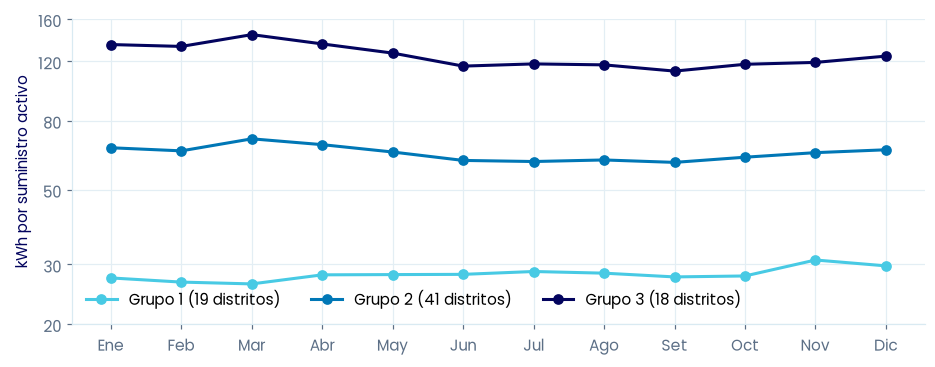

Grupo 1: Ayabaca, Canchaque, Chalaco, El Carmen De La Frontera, Frias, Huarmaca, Lagunas, Lalaquiz, Montero, Pacaipampa, San Juan De Bigote, San Miguel De El Faique, Santa Catalina De Mossa, Santo Domingo, Sapillica, Sicchez, Sondor, Sondorillo, Yamango
Grupo 2: 26 De Octubre, Amotape, Arenal, Bellavista De La Union, Bernal, Buenos Aires, Casitas, Chulucanas, Colan, Corrales, Cristo Nos Valga, Cura Mori, El Tallan, Huancabamba, Ignacio Escudero, Jilili, La Arena, La Brea, La Huaca, La Matanza, La Union, Lancones, Las Lomas, Marcavelica, Matapalo, Miguel Checa, Morropon, Paimas, Pampas De Hospital, Papayal, Querecotillo, Rinconada Llicuar, Salitral, Salitral, San Jacinto, San Juan De La Virgen, Suyo, Tamarindo, Tambogrande, Vice, Vichayal
Grupo 3: Aguas Verdes, Bellavista, Canoas De Punta Sal, Castilla, Catacaos, El Alto, La Cruz, Lobitos, Los Organos, Mancora, Paita, Parinas, Piura, Sechura, Sullana, Tumbes, Zarumilla, Zorritos


In [4]:
km = kmeans_distritos(pn)
G = pd.DataFrame(resumen_grupos(km, pn)).set_index("grupo")
G["mes_max"] = [MESES[m - 1] for m in G["max_mes"]]
display(G[["n_distritos", "suministros_dic2025", "consumo_medio", "mes_max", "amplitud"]].round(2))
fig, ax = plt.subplots()
for g, fila in G.iterrows():
    ax.plot(
        range(12),
        fila["perfil"],
        color=COLOR_GRUPO[g],
        marker="o",
        lw=2,
        label=f"Grupo {g} ({fila['n_distritos']} distritos)",
    )
ax.set_xticks(range(12), MESES)
ax.set_yscale("log")
ax.set_yticks([20, 30, 50, 80, 120, 160], ["20", "30", "50", "80", "120", "160"])
ax.minorticks_off()
ax.set_ylabel("kWh por suministro activo")
ax.legend(ncol=3)
plt.show()
for g, fila in G.iterrows():
    print(f"Grupo {g}:", ", ".join(d.title() for d in fila["distritos"]))

El **grupo 1** reúne distritos de la sierra de Piura con el menor consumo; el **grupo 2**, distritos de consumo intermedio; el **grupo 3**, capitales y distritos de la costa, con el mayor consumo y la mayor estacionalidad (máximo en marzo, en verano).

<a id="visualización-con-pca"></a>

## 5. Visualización con PCA

El análisis de componentes principales proyecta los perfiles sobre las direcciones ortogonales de mayor varianza; la proporción de varianza explicada indica cuánta información conserva el plano (Jolliffe y Cadima, 2016). Aquí se usa solo para **visualizar** los grupos, no para formarlos.

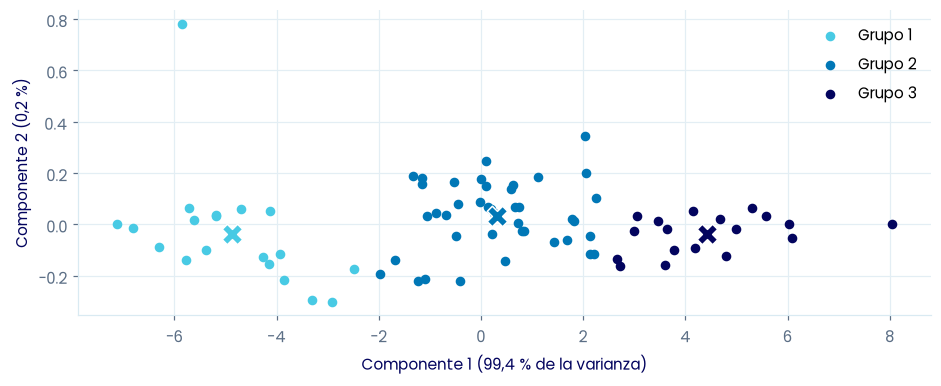

In [5]:
pc = proyeccion_pca(km)
fig, ax = plt.subplots()
for g in (1, 2, 3):
    pts = np.array([pc["puntos"][u] for u in km.grupo.index if km.grupo[u] == g])
    ax.scatter(pts[:, 0], pts[:, 1], s=28, color=COLOR_GRUPO[g], label=f"Grupo {g}")
    ax.scatter(*pc["centroides"][g], marker="X", s=180, color=COLOR_GRUPO[g], edgecolor="white")
v1, v2 = pc["varianza"]
ax.set(
    xlabel=f"Componente 1 ({coma(v1 * 100, 1)} % de la varianza)",
    ylabel=f"Componente 2 ({coma(v2 * 100, 1)} %)",
)
ax.legend()
plt.show()

La primera componente explica el **99,4 %** de la varianza: los doce meses de un distrito suben y bajan casi juntos, de modo que los grupos se separan sobre todo por **nivel de consumo** y aparecen como tramos sucesivos de esa componente. Las diferencias de estacionalidad existen, pero pesan poco en el agrupamiento.

<a id="contraste-con-el-agrupamiento-jerárquico"></a>

## 6. Contraste con el agrupamiento jerárquico

Para saber si los grupos son robustos o un artefacto de k-means, se repite el agrupamiento con un método distinto. El **jerárquico aglomerativo** une en cada paso los dos grupos cuya fusión produce el menor aumento de la suma de cuadrados (enlace de **Ward**; Ward, 1963). El árbol (dendrograma) se corta en 3 grupos y se compara con k-means mediante el **índice de Rand ajustado**: 1 si las particiones son idénticas y cerca de 0 si coinciden como al azar (Hubert y Arabie, 1985).

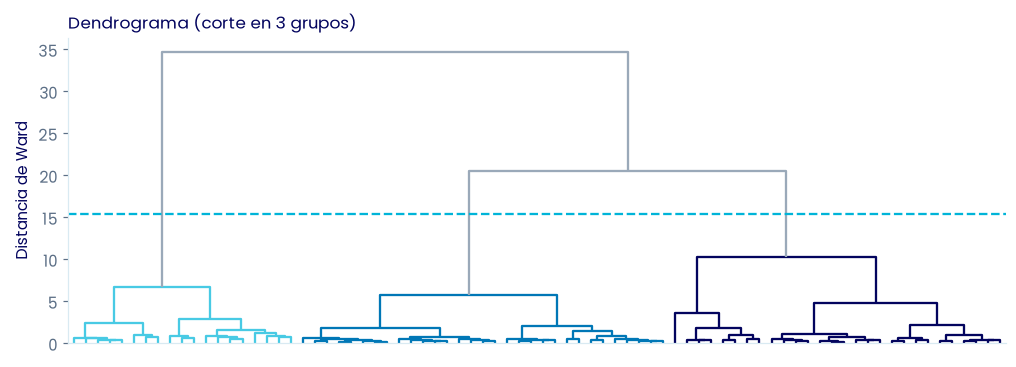

Índice de Rand ajustado frente a k-means: 0,646


,2,3,4,5,6,7,8,9,10
k-means,0.5420,0.5870,0.5640,0.5210,0.5110,0.5140,0.5200,0.5030,0.4920
jerárquico,0.6000,0.5750,0.5720,0.5240,0.5010,0.5120,0.5140,0.4960,0.4890


In [6]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage, set_link_color_palette

Z = linkage(X, method="ward")
sil_j = {k: silhouette_score(X, fcluster(Z, k, "maxclust")) for k in ks}
etiquetas_j = fcluster(Z, 3, "maxclust")
ari = adjusted_rand_score(km.grupo.loc[perfiles.index], etiquetas_j)
set_link_color_palette([AQUA, BLUE, NAVY])
corte = (Z[-3, 2] + Z[-2, 2]) / 2
fig, ax = plt.subplots(figsize=(11, 3.6))
dendrogram(Z, ax=ax, no_labels=True, color_threshold=corte, above_threshold_color=GRIS)
ax.axhline(corte, color=CYAN, ls="--")
ax.set(ylabel="Distancia de Ward", title="Dendrograma (corte en 3 grupos)")
ax.grid(False)
plt.show()
print(f"Índice de Rand ajustado frente a k-means: {coma(ari, 3)}")
pd.DataFrame({"k-means": sil, "jerárquico": sil_j}).T.round(3)

In [7]:
jq = jerarquico_distritos(km)  # misma comparación con la numeración de grupos por consumo
pd.DataFrame(jq["coincidencias"]).T.rename_axis(index="k-means", columns="jerárquico")

jerárquico,1,2,3
k-means,,,
1,19,0,0
2,0,31,10
3,0,0,18


Ambos métodos coinciden en **68 de los 78 distritos** (Rand ajustado 0,646). Las 10 diferencias son distritos que k-means asigna al grupo 2 y el jerárquico une al grupo 3: los de consumo intermedio más alto, en la frontera entre ambos. El jerárquico prefiere 2 grupos (silueta 0,600) y k-means 3; se mantiene k-means, que tiene la mayor silueta con tres grupos.

<a id="detección-de-atípicos-con-dbscan"></a>

## 7. Detección de atípicos con DBSCAN

DBSCAN forma grupos con las regiones densas: un punto es central si tiene al menos `min_samples` vecinos a menos de $\varepsilon$; los puntos que no son centrales ni están cerca de uno son **ruido** (Ester et al., 1996). No hay que fijar el número de grupos, y el ruido es justamente lo que interesa: los distrito-meses que no se parecen a ningún otro.

Cada distrito-mes se describe con tres variables estandarizadas: el nivel $\ln y_t$, la variación mensual $\ln(y_t/y_{t-1})$ y la interanual $\ln(y_t/y_{t-12})$. Siguiendo a Schubert et al. (2017), `min_samples` = 2 × 3 = 6 y $\varepsilon$ se fija en el codo (la «rodilla») de la curva ordenada de distancias al sexto vecino: el punto más alejado de la recta que une sus extremos.

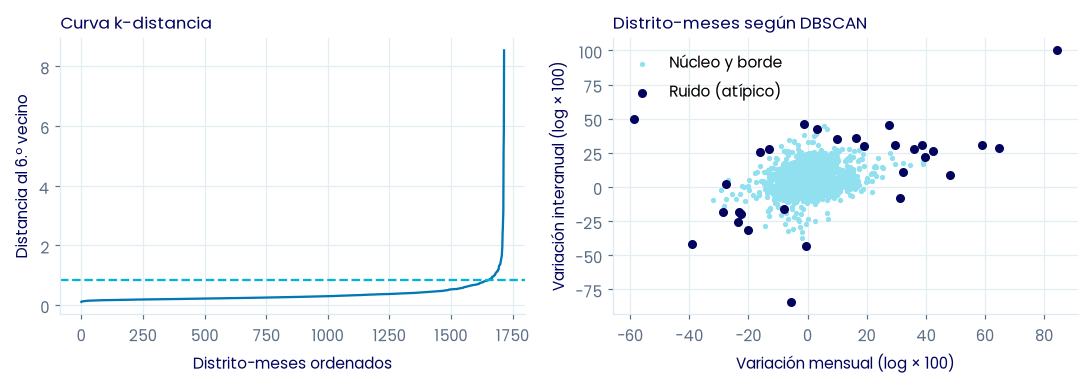

ε = 0,837 · 1716 distrito-meses evaluados
30 atípicos (1,7 %) en 1 grupo denso


In [8]:
pr = car.agregar_rezagos(pn).dropna(subset=["lag1", "lag12"])
Zd = np.column_stack([np.log(pr["y"]), np.log(pr["y"] / pr["lag1"]), np.log(pr["y"] / pr["lag12"])])
Zs = StandardScaler().fit_transform(Zd)
kdist = np.sort(NearestNeighbors(n_neighbors=6).fit(Zs).kneighbors(Zs)[0][:, -1])
eps = rodilla(kdist)
etiquetas = DBSCAN(eps=eps, min_samples=6).fit(Zs).labels_
ruido = etiquetas == -1
fig, (a1, a2) = plt.subplots(1, 2)
a1.plot(kdist, color=BLUE)
a1.axhline(eps, color=CYAN, ls="--")
a1.set(
    title="Curva k-distancia", xlabel="Distrito-meses ordenados", ylabel="Distancia al 6.º vecino"
)
a2.scatter(Zd[~ruido, 1] * 100, Zd[~ruido, 2] * 100, s=6, color=SKY, label="Núcleo y borde")
a2.scatter(Zd[ruido, 1] * 100, Zd[ruido, 2] * 100, s=24, color=NAVY, label="Ruido (atípico)")
a2.set(
    title="Distrito-meses según DBSCAN",
    xlabel="Variación mensual (log × 100)",
    ylabel="Variación interanual (log × 100)",
)
a2.legend()
plt.tight_layout()
plt.show()
print(f"ε = {coma(eps, 3)} · {len(pr)} distrito-meses evaluados")
n_grupos = len(set(etiquetas) - {-1})
print(f"{ruido.sum()} atípicos ({coma(ruido.mean() * 100, 1)} %) en {n_grupos} grupo denso")

In [9]:
at = pr[ruido].merge(km.grupo, left_on="UBIGEO", right_index=True)
at = at.assign(var_mes=at["y"] / at["lag1"] - 1).sort_values("var_mes", key=abs, ascending=False)
display(at[["DIST_N", "PROV_N", "PERIODO", "lag1", "y", "var_mes", "grupo"]].head(8))
print("Atípicos por grupo:", at["grupo"].value_counts().sort_index().to_dict())
print(
    "Mes con más atípicos:",
    at["PERIODO"].value_counts().idxmax(),
    at["PERIODO"].value_counts().max(),
)

,DIST_N,PROV_N,PERIODO,lag1,y,var_mes,grupo
591,SAPILLICA,AYABACA,202502,22.0060,51.0972,1.3220,1
1144,SALITRAL,MORROPON,202511,35.0962,67.0430,0.9103,2
770,EL CARMEN DE LA FRONTERA,HUANCABAMBA,202511,19.2539,34.6836,0.8014,1
1178,SAN JUAN DE BIGOTE,MORROPON,202511,31.8267,51.4699,0.6172,1
1173,SAN JUAN DE BIGOTE,MORROPON,202506,32.8670,50.2430,0.5287,1
1076,LA MATANZA,MORROPON,202511,49.7318,74.0162,0.4883,2
833,LALAQUIZ,HUANCABAMBA,202506,17.5632,25.8122,0.4697,1
592,SAPILLICA,AYABACA,202503,51.0972,28.4216,-0.4438,1


Atípicos por grupo: {1: 19, 2: 10, 3: 1}
Mes con más atípicos: 202511 6


DBSCAN forma un solo grupo denso y marca **30 distrito-meses** como ruido, 19 de ellos en distritos pequeños de la sierra (grupo 1), donde un cambio chico en kWh es una variación porcentual grande; noviembre de 2025 concentra 6. No se eliminan: no se puede saber si son cambios reales o ajustes de facturación, y el notebook 3 los usa para analizar dónde se equivoca el modelo.

<a id="exportación-del-modelo-k-means"></a>

## 8. Exportación del modelo k-means

Se guarda el escalador, el modelo y la numeración de los grupos, para asignar el grupo de un perfil nuevo con el mismo criterio, junto con un archivo de metadatos: qué datos se usaron, con qué semilla y con qué métricas.

In [10]:
import joblib

escalador = StandardScaler().fit(np.log(perfiles.values))
modelo = KMeans(n_clusters=3, n_init=20, random_state=config.SEMILLA).fit(
    escalador.transform(np.log(perfiles.values))
)
orden = {int(e): int(km.grupo.iloc[i]) for i, e in enumerate(modelo.labels_)}
assert all(orden[int(e)] == km.grupo.iloc[i] for i, e in enumerate(modelo.labels_))
carpeta = config.RAIZ / "modelos"
carpeta.mkdir(exist_ok=True)
joblib.dump(
    {
        "escalador": escalador,
        "kmeans": modelo,
        "grupo_de_etiqueta": orden,
        "meses": list(perfiles.columns),
    },
    carpeta / "kmeans_distritos.joblib",
)
meta = {
    "modelo": "k-means (scikit-learn)",
    "entrada": "consumo medio mensual por distrito, 2024-2025, logaritmo y estandarizado",
    "k": 3,
    "semilla": config.SEMILLA,
    "silueta": round(float(sil[3]), 4),
    "distritos_por_grupo": {int(g): int(n) for g, n in G["n_distritos"].items()},
    "rand_ajustado_vs_jerarquico": round(float(ari), 4),
    "varianza_pca_componente_1": round(float(pc["varianza"][0]), 4),
    "versiones": VERSIONES,
}
(carpeta / "kmeans_distritos.json").write_text(
    json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf8"
)
meta

{'modelo': 'k-means (scikit-learn)',
 'entrada': 'consumo medio mensual por distrito, 2024-2025, logaritmo y estandarizado',
 'k': 3,
 'semilla': 42,
 'silueta': 0.5871,
 'distritos_por_grupo': {1: 19, 2: 41, 3: 18},
 'rand_ajustado_vs_jerarquico': 0.6463,
 'varianza_pca_componente_1': 0.9937,
 'versiones': {'numpy': '2.4.6',
  'pandas': '3.1.1',
  'scikit-learn': '1.9.1',
  'scipy': '1.17.1',
  'xgboost': '3.2.0',
  'matplotlib': '3.11.2'}}

<a id="verificación-con-el-informe"></a>

## 9. Verificación con el informe

In [11]:
assert km.k == INFORME["kmeans_k"] and abs(sil[3] - INFORME["kmeans_silueta"]["3"]) < 1e-12
assert {u: int(g) for u, g in km.grupo.items()} == INFORME["kmeans_asignacion"]
assert abs(pc["varianza"][0] - INFORME["kmeans_pca"]["varianza"][0]) < 1e-12
assert abs(ari - INFORME["jerarquico"]["ari"]) < 1e-12
db = dbscan_atipicos(car.agregar_rezagos(pn))
assert abs(eps - INFORME["dbscan"]["eps"]) < 1e-12 and ruido.sum() == INFORME["dbscan"][
    "ruido"
] == len(db.ruido)
print("Grupos, PCA, jerárquico y DBSCAN coinciden con el informe.")

print(f"Tiempo de ejecución del notebook: {time.time() - INICIO:.0f} s")

Grupos, PCA, jerárquico y DBSCAN coinciden con el informe.
Tiempo de ejecución del notebook: 4 s


<a id="conclusiones"></a>

## 10. Conclusiones

- k-means con **k = 3** (silueta 0,587) separa los distritos sobre todo por **nivel de consumo**, como muestra PCA (componente 1: 99,4 % de la varianza).
- El agrupamiento jerárquico de Ward llega casi a la misma estructura (68 de 78 distritos; Rand ajustado 0,646): el resultado no depende del método.
- DBSCAN detecta **30 distrito-meses atípicos**, concentrados en la sierra.
- El grupo de cada distrito pasa como variable de entrada a los modelos supervisados del notebook 3.

<a id="referencias"></a>

## 11. Referencias

- Ester, M., Kriegel, H.-P., Sander, J. y Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. En *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96)* (pp. 226–231). AAAI Press. https://cdn.aaai.org/KDD/1996/KDD96-037.pdf
- Hubert, L. y Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075
- Jolliffe, I. T. y Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A: Mathematical, Physical and Engineering Sciences, 374*(2065), Artículo 20150202. https://doi.org/10.1098/rsta.2015.0202
- Lloyd, S. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory, 28*(2), 129–137. https://doi.org/10.1109/TIT.1982.1056489
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Schubert, E., Sander, J., Ester, M., Kriegel, H.-P. y Xu, X. (2017). DBSCAN revisited, revisited: Why and how you should (still) use DBSCAN. *ACM Transactions on Database Systems, 42*(3), Artículo 19. https://doi.org/10.1145/3068335
- Ward, J. H., Jr. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845